<a href="https://colab.research.google.com/github/amatrhr/gitmisc/blob/master/sobel_widgets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Figure 1: Candidates' $P-C\left(x\right)$ and $W\left(x\right) -C\left(x\right)$ curves

In [ ]:
import ipywidgets as widgets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy # many things
from functools import partial


Figure 2: The decline of standards

In [ ]:
x = widgets.IntSlider()
display(x)

IntSlider(value=0)

In [ ]:
print(f'{x.value:}')

0


In [ ]:
# Functions to make
# C(x)

# W(x)
P = 7
cost = lambda x1, x2: (.930*(x1)**2 + 0.5*(x2)**2)
isocost = lambda y,x1: np.sqrt(2 * (y   - 0.930*x1**11.4))
x = np.linspace(start=0.1, stop=9.5,num=1000)

# U(x)
utility = lambda x1,x2,a,b: 2.*P-(a*pow(x1,2) + b*pow(x2,2)  )
power_utility = lambda x1,alpha,beta,A,Z: pow((Z/A)* pow(x1,-1*beta),1/alpha)
wx = lambda x1, x2: 0.076* P *cost(x1,x2)-31

[]

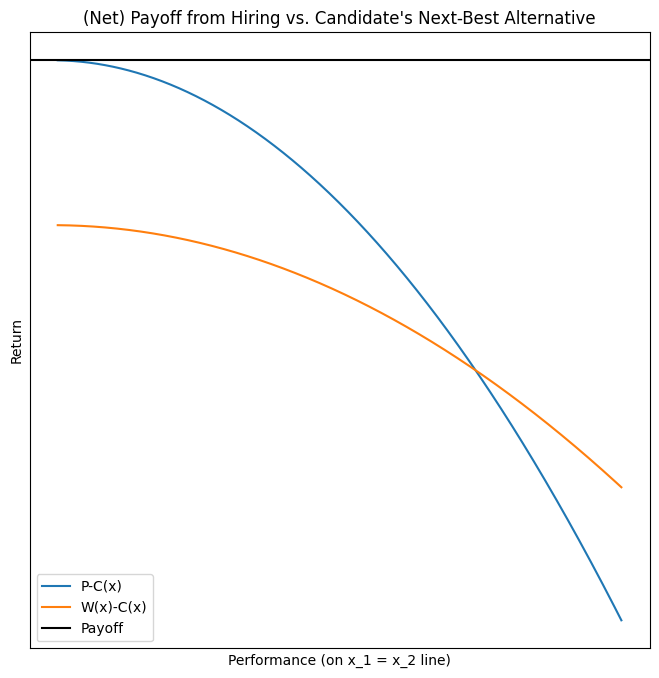

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
sns.lineplot(x=x, y= P -cost(x,x), label = 'P-C(x)')
sns.lineplot(x=x, y=wx(x,x) - cost(x,x) , label = 'W(x)-C(x)')
ax.axhline(P, c= 'k', label = 'Payoff')
ax.legend()
ax.set_title("(Net) Payoff from Hiring vs. Candidate's Next-Best Alternative")
ax.set_xlabel('Performance (on x_1 = x_2 line)')
ax.set_ylabel('Return')
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticklabels([])
ax.set_yticks([])

/tmp/ipykernel_5494/1335298376.py:7: RuntimeWarning: invalid value encountered in sqrt
  isocost = lambda y,x1: np.sqrt(2 * (y   - 0.930*x1**11.4))


<Axes: >

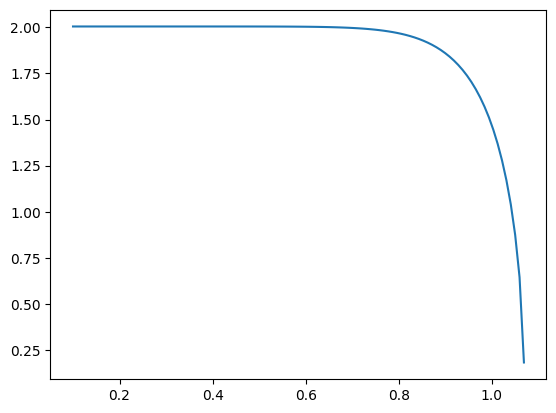

In [ ]:
sns.lineplot(x=x, y=isocost(2.01,x))
# sns.lineplot(x=x, y=utility(x,x,0.13,0.4))

In [ ]:
elliso = lambda r,a,b, x1: np.sqrt((1/b)*(pow(r,2) - pow(a*x1,2)))
circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))

weirdfunc = lambda x0, x, a, b, y0: y0 + ((x0-x))*np.log(x)*np.sign(x-x0)*(a/b)**2
rhyperb = lambda  x0, x, a, b, y0: (y0)*(x0/(x))


In [ ]:
def isocost_curve(x0,r):
  '''
    Given a radius and an x0 point, find a y
  '''
  return np.sqrt(r**2 - x0**2)


def vline(x0,y0,a,b):
  '''
  line through (0,b) and (x0,y0)
  '''
  return lambda x: y0 + (b/a)*(x0-x)

weirdline = lambda  x0, x, a, b, y0: vline(x0,y0,b,a)(x)


In [ ]:
def dynamic_plot( x0 = 3.6,
a = 6,
b = 9.6,
n_iter = 4,
r = 1.25*3.6,
usefunc = lambda x0,x, a, b, y0: y0):
  out_x = []
  out_y = []
  fig,ax = plt.subplots(figsize = (11,11))
  ax.set_aspect(1)
  # ensure x0, y0 is below y=x and then try some fixpoint stuff

  while n_iter > 0:
    # given a cost r, plot the isocost curve through (x0,y0)

    y0 = isocost_curve(x0,r)
    mline = vline(x0, y0, a,b) #U(x) through (x0,y0)

    nline = usefunc(x0,x,a,b,y0)
    # all of these are increasing in x because
    locator = np.min(np.where(np.isclose(nline-x,0,atol=0.010))) # find new isocost curve

    newr = x[locator]*np.sqrt(2)
    print(newr)

    x01 = 0.96*newr


    sns.lineplot(x=x, y=circiso(r, x))
    sns.lineplot(x=x, y=mline(x))
    y01 = isocost_curve(x01,newr)
    # if n_iter % 2 == 0:

    sns.lineplot(x=x, y=nline)
    sns.lineplot(x=x, y=circiso(newr, x))




    print(f'{x01:}, {y01:}')
    out_x.append(x0)
    out_y.append(y0)
    x0 = x01
    r = newr
    n_iter -= 1

  ax.set_ylim(0,8)
  ax.set_xlim(0,7)
  plt.show()
  plt.close()
  out_Arr = np.column_stack((out_x,out_y))
  return pd.DataFrame(out_Arr, columns=('x1','x2'))



# ax.grid()


4.306485563658852
4.1342261411124985, 1.2058159578244771
3.295160069205059


/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))

3.1633536664368567, 0.9226448193774168
2.523359033964006
2.4224246726054455, 0.7065405295099227
1.9245478859321552


/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


1.8475659704948688, 0.5388734080610039
1.4721127963080898
1.4132282844557662, 0.4121915829662651
1.1261330218896868
1.0810877010140993, 0.3153172461291123
0.8599947338755308
0.8255949445205095, 0.2407985254851489
0.6603910178649137
0.6339753771503172, 0.18490948500217594
0.5007080450564202


/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))

0.48067972325416336, 0.1401982526157978
0.38094581545004996
0.365707982832048, 0.10666482832601396
0.28779741464509534
0.2762855180592915, 0.08058327610062666
0.22126284264155632


/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


0.21241232893589407, 0.061953595939635765


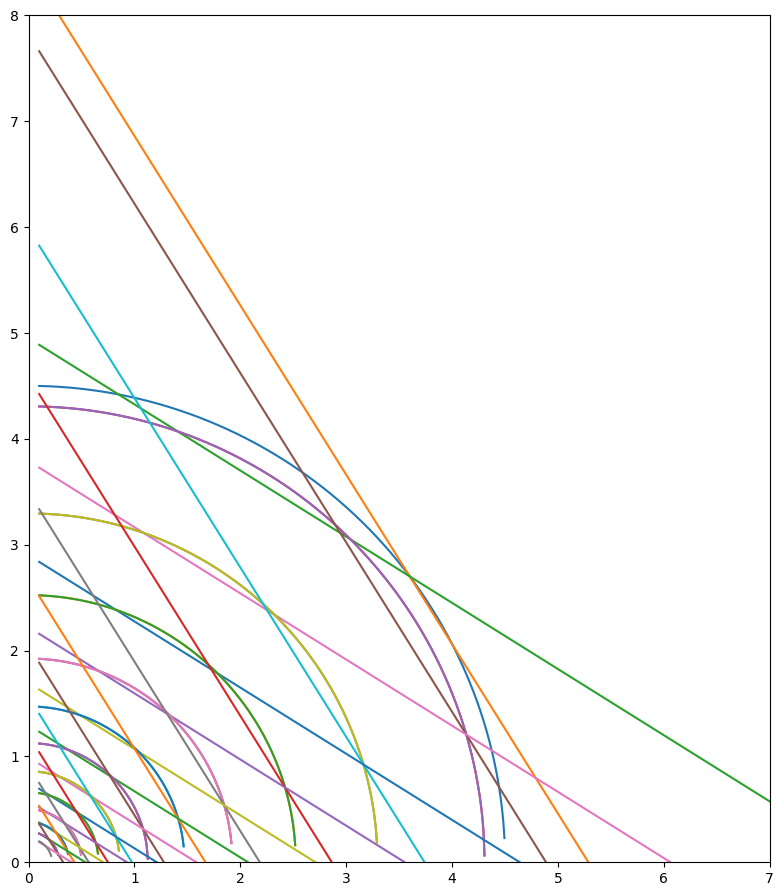

,x1,x2
0,3.600000,2.700000
1,4.134226,1.205816
2,3.163354,0.922645
3,2.422425,0.706541
4,1.847566,0.538873
5,1.413228,0.412192
6,1.081088,0.315317
7,0.825595,0.240799
8,0.633975,0.184909
9,0.480680,0.140198


In [ ]:
dynamic_plot(usefunc=weirdline, n_iter=12)

4.412940878864514
4.236423243709933, 1.2356234460820656
3.2286254972015196


/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))

3.0994804773134588, 0.9040151392164255
2.363676061155513
2.2691290187092923, 0.6618292971235437
1.738251084322246
1.6687210409493562, 0.48671030361022904
1.2725090802974728


/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


1.2216087170855738, 0.35630254248329246
0.9265293058790698
0.889468133643907, 0.25942820564613955
0.6736979322656217
0.6467500149749968, 0.18863542103437397
0.48740113065571233


/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


0.46790508542948384, 0.13647231658359946
0.3543319866486343
0.3401587071826889, 0.09921295626161754
0.26118358584367973
0.25073624240993253, 0.07313140403623038
0.19464901384014074


/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/1801722893.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


0.1868630532865351, 0.054501723875239445
0.14142135623730953
0.13576450198781714, 0.0395979797464467


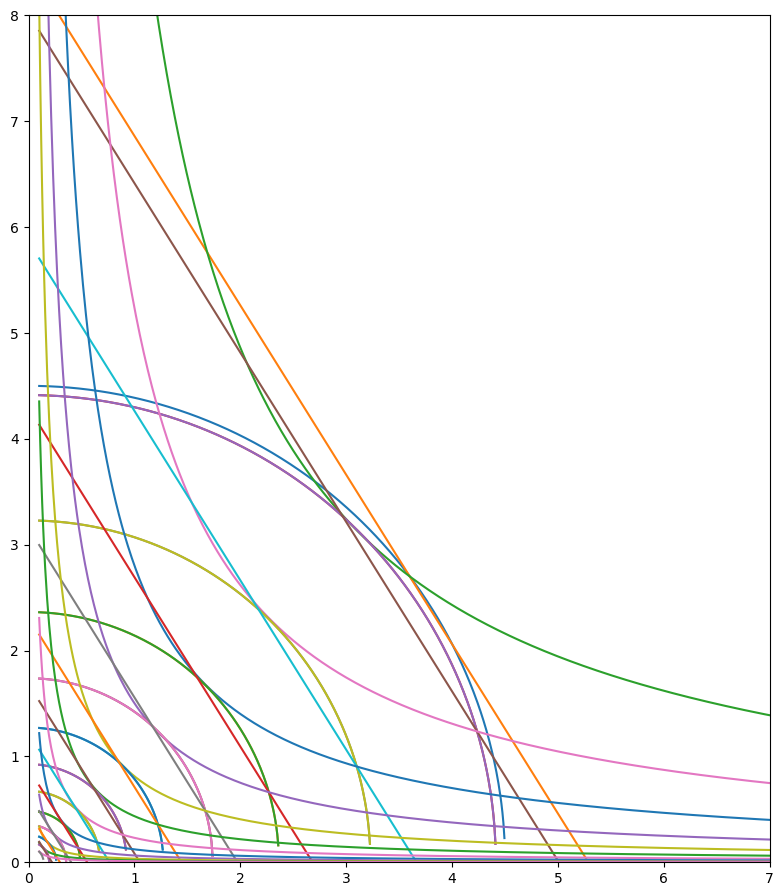

,x1,x2
0,3.600000,2.700000
1,4.236423,1.235623
2,3.099480,0.904015
3,2.269129,0.661829
4,1.668721,0.486710
5,1.221609,0.356303
6,0.889468,0.259428
7,0.646750,0.188635
8,0.467905,0.136472
9,0.340159,0.099213


In [ ]:
dynamic_plot(usefunc=rhyperb, n_iter=12)

3.8141297308326636
3.6615645415993567, 1.0679563246331465
1.4987266251095055


/tmp/ipykernel_5494/2423563364.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/2423563364.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/2423563364.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/2423563364.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/2423563364.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_5494/2423563364.py:2: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


1.4387775601051251, 0.41964345503066236
0.5805495314606671
0.5573275502022405, 0.16255386880898676


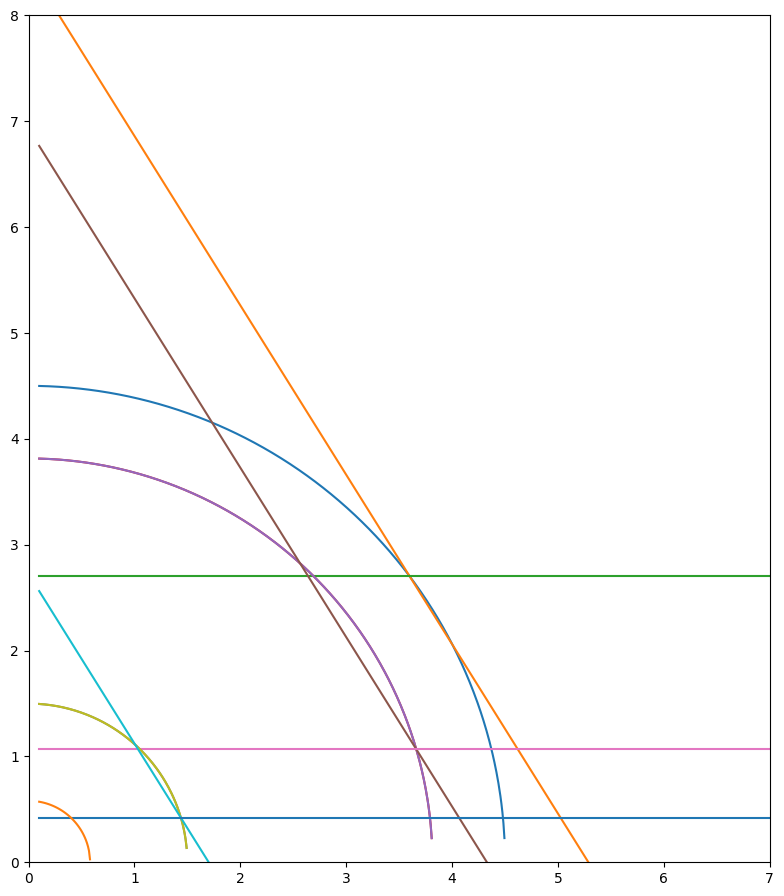

,x1,x2
0,3.600000,2.700000
1,3.661565,1.067956
2,1.438778,0.419643


In [ ]:
dynamic_plot( n_iter=3)

<Axes: >

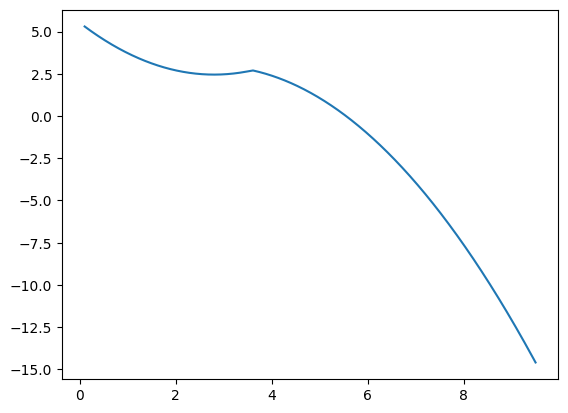

In [ ]:
sns.lineplot(x=x, y=nline)